# BloodLink – Advanced Network Analysis

This notebook examines isolated blood banks, connected geographical groups and important nodes in the BloodLink network.

## Step 1 : Load network results

In [2]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path

# Load previously exported network results
results_folder = Path("results")
nodes_file = "bloodlink_network_nodes.csv"
edges_file = "bloodlink_network_edges.csv"

if not (results_folder / nodes_file).is_file() or not (results_folder / edges_file).is_file():
    for parent in (Path.cwd(), *Path.cwd().parents):
        candidate = parent / "results"
        if (candidate / nodes_file).is_file() and (candidate / edges_file).is_file():
            results_folder = candidate
            break

nodes = pd.read_csv(
    results_folder / "bloodlink_network_nodes.csv"
)

edges = pd.read_csv(
    results_folder / "bloodlink_network_edges.csv"
)

# Reconstruct the geographical network
G = nx.from_pandas_edgelist(
    edges,
    source="source",
    target="target",
    edge_attr=True,
    create_using=nx.Graph()
)

# Add all blood banks, including isolated nodes
for _, row in nodes.iterrows():
    G.add_node(
        row["bank_id"],
        name=row["name"],
        state=row["state"],
        district=row["district"],
        lat=row["lat"],
        lon=row["lon"]
    )

print("Network loaded successfully!")
print("Total Nodes:", G.number_of_nodes())
print("Total Edges:", G.number_of_edges())

Network loaded successfully!
Total Nodes: 2439
Total Edges: 10248


## 1. Isolated Blood Bank Analysis

An isolated node is a blood bank that has no other blood bank within the selected 10 km geographical distance threshold.

## Step 2 : Identify isolated blood banks

In [3]:
isolated_bank_ids = list(nx.isolates(G))

isolated_banks = nodes[
    nodes["bank_id"].isin(isolated_bank_ids)
].copy()

print("Total Isolated Blood Banks:", len(isolated_banks))

display(
    isolated_banks[
        ["bank_id", "name", "state", "district", "lat", "lon"]
    ].head(15)
)

Total Isolated Blood Banks: 624


,bank_id,name,state,district,lat,lon
7,BB8,South Central Railway Hospital Blood Bank,andhra-pradesh,Anantapur,15.17289,77.36610
8,BB9,Indian Red Cross Society Blood Bank,andhra-pradesh,Anantapur,13.83253,77.49221
9,BB10,Indian Red Cross Society Blood bank RCH -II KA...,andhra-pradesh,Anantapur,14.11309,78.15737
10,BB11,S.S.S.I.H.M.S. Blood Bank,andhra-pradesh,Anantapur,14.15189,77.77685
14,BB15,M/s PESIMSR Blood Bank.,andhra-pradesh,Chittoor,12.79122,78.36390
16,BB17,"Indian Red Cross Society, Madanapalli RCH 2",andhra-pradesh,Chittoor,13.55693,78.50085
29,BB30,M/s. Government Area General Hospital Blood Bank.,andhra-pradesh,East Godavari,17.35494,82.54124
35,BB36,Katuri Medical College and Hospital Blood Bank,andhra-pradesh,Guntur,16.22787,80.30947
40,BB41,Anjireddy Multi Specality Blood Bank,andhra-pradesh,Guntur,16.47879,79.89364
41,BB42,Red Cross Blood Bank,andhra-pradesh,Guntur,16.01743,80.82948


## 2. Connected Geographical Groups

A connected component is a group of blood banks where every bank can be reached from another bank through one or more network connections.

This analysis helps identify clusters of geographically connected blood banks.

## Step 3 : Connected component analysis

In [4]:
# Identify all connected components
components_list = list(nx.connected_components(G))

# Calculate the size of each component
component_sizes = sorted(
    [len(component) for component in components_list],
    reverse=True
)

print("Total Connected Groups:", len(component_sizes))
print("Largest Group Size:", component_sizes[0])
print("Second Largest Group Size:", component_sizes[1] if len(component_sizes) > 1 else 0)

print("\nTop 10 Connected Groups:")
display(pd.DataFrame({
    "Group Number": range(1, min(10, len(component_sizes)) + 1),
    "Number of Blood Banks": component_sizes[:10]
}))

Total Connected Groups: 960
Largest Group Size: 109
Second Largest Group Size: 80

Top 10 Connected Groups:


,Group Number,Number of Blood Banks
0,1,109
1,2,80
2,3,67
3,4,62
4,5,47
5,6,42
6,7,31
7,8,26
8,9,25
9,10,20


## Step 4 : Visualize the largest groups

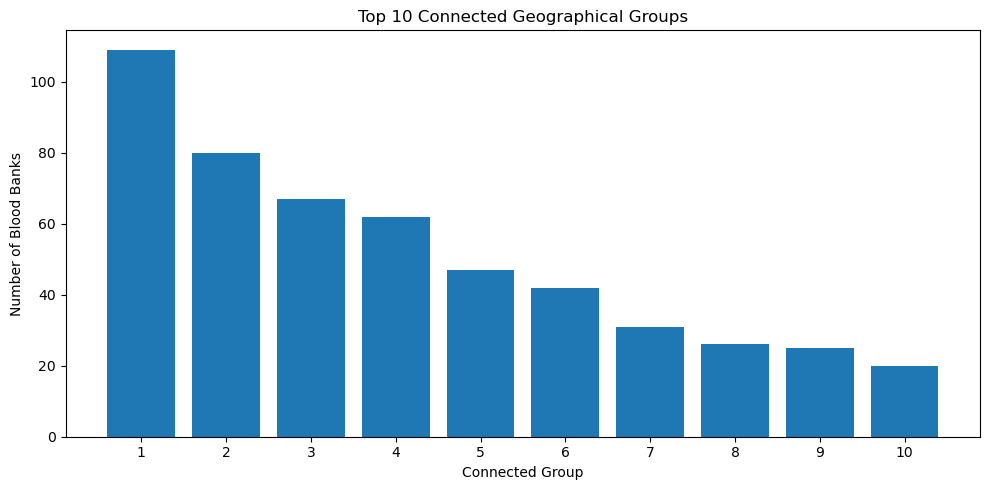

In [5]:
top_components = component_sizes[:10]

plt.figure(figsize=(10, 5))

plt.bar(
    range(1, len(top_components) + 1),
    top_components
)

plt.xlabel("Connected Group")
plt.ylabel("Number of Blood Banks")
plt.title("Top 10 Connected Geographical Groups")

plt.xticks(range(1, len(top_components) + 1))
plt.tight_layout()
plt.show()

## 3. Important Blood Banks Based on Network Connections

This section identifies blood banks with the highest number of direct geographical connections.

A higher degree indicates that more listed blood banks are located within the selected 10 km threshold.

## Step 5 : Identify highly connected blood banks

In [6]:
# Calculate the number of direct connections
bank_degrees = dict(G.degree())

important_banks = pd.DataFrame({
    "bank_id": list(bank_degrees.keys()),
    "number_of_connections": list(bank_degrees.values())
})

important_banks = important_banks.merge(
    nodes[["bank_id", "name", "state", "district"]],
    on="bank_id",
    how="left"
)

important_banks = important_banks.sort_values(
    "number_of_connections",
    ascending=False
)

print("Top 10 Most Connected Blood Banks:")
display(important_banks.head(10))

Top 10 Most Connected Blood Banks:


,bank_id,number_of_connections,name,state,district
1058,BB1983,56,Rudhira Voluntary Blood Bank,telangana,Hyderabad
1059,BB1984,56,Satya Nursing Home Blood Bank,telangana,Hyderabad
1060,BB1985,56,Aditya Hospital Blood Bank,telangana,Hyderabad
1074,BB2001,56,Lions Club Matadin Goel Blood Bank,telangana,Hyderabad
1057,BB1982,56,Sanjeevini Blood Bank,telangana,Hyderabad
1077,BB2004,56,Kamineni Health Services Pvt.Ltd. Blood Bank,telangana,Hyderabad
1082,BB2009,56,Institute of Preventive Medicine,telangana,Hyderabad
1069,BB1996,56,Share Medical Care (Mediciti Hospital) Blood Bank,telangana,Hyderabad
1073,BB2000,56,Apollo Hospital Enterprises Ltd,telangana,Hyderabad
1089,BB2016,56,Gandhi Hospital Blood Bank,telangana,Hyderabad


## Step 6 : Visualize important blood banks

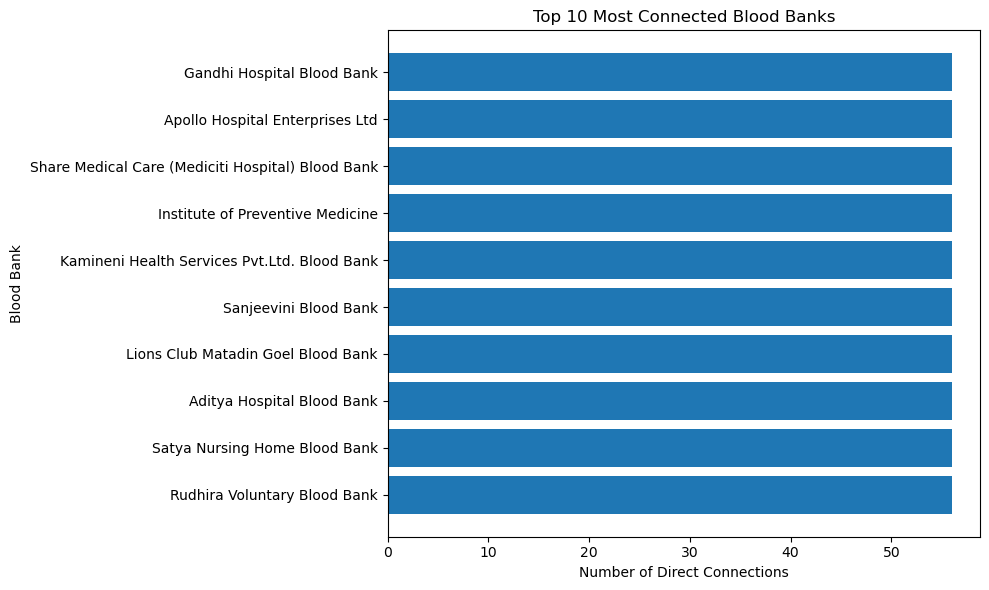

In [7]:
top_important_banks = (
    important_banks.head(10)
    .sort_values("number_of_connections")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_important_banks["name"],
    top_important_banks["number_of_connections"]
)

plt.xlabel("Number of Direct Connections")
plt.ylabel("Blood Bank")
plt.title("Top 10 Most Connected Blood Banks")

plt.tight_layout()
plt.show()

## 4. Karnataka Network Analysis

This section examines the geographical network formed by blood banks located in Karnataka.

## Step 7 : Karnataka network analysis

In [8]:
karnataka_nodes = nodes[
    nodes["state"].str.strip().str.lower() == "karnataka"
].copy()

karnataka_bank_ids = set(karnataka_nodes["bank_id"])

karnataka_G = G.subgraph(karnataka_bank_ids).copy()

print("Karnataka Network Summary")
print("-------------------------")
print("Total Blood Banks:", karnataka_G.number_of_nodes())
print("Total Connections:", karnataka_G.number_of_edges())
print(
    "Connected Components:",
    nx.number_connected_components(karnataka_G)
)
print(
    "Average Degree:",
    round(np.mean([degree for _, degree in karnataka_G.degree()]), 2)
    if karnataka_G.number_of_nodes() > 0 else 0
)

Karnataka Network Summary
-------------------------
Total Blood Banks: 192
Total Connections: 1522
Connected Components: 52
Average Degree: 15.85


## 5. India and Karnataka Network Comparison

This section compares the geographical network structure of India and Karnataka using network statistics.

## Step 8 : India vs Karnataka comparison

In [9]:
def calculate_network_metrics(graph, region):
    node_count = graph.number_of_nodes()
    edge_count = graph.number_of_edges()

    return {
        "Region": region,
        "Blood Banks": node_count,
        "Connections": edge_count,
        "Average Degree": round(
            np.mean([degree for _, degree in graph.degree()]), 2
        ) if node_count > 0 else 0,
        "Network Density": round(nx.density(graph), 4),
        "Connected Components": nx.number_connected_components(graph),
        "Isolated Banks": len(list(nx.isolates(graph)))
    }


comparison_data = pd.DataFrame([
    calculate_network_metrics(G, "India"),
    calculate_network_metrics(karnataka_G, "Karnataka")
])

display(comparison_data)

,Region,Blood Banks,Connections,Average Degree,Network Density,Connected Components,Isolated Banks
0,India,2439,10248,8.40,0.0034,960,624
1,Karnataka,192,1522,15.85,0.0830,52,28


## step 9 : Visualize the comparison

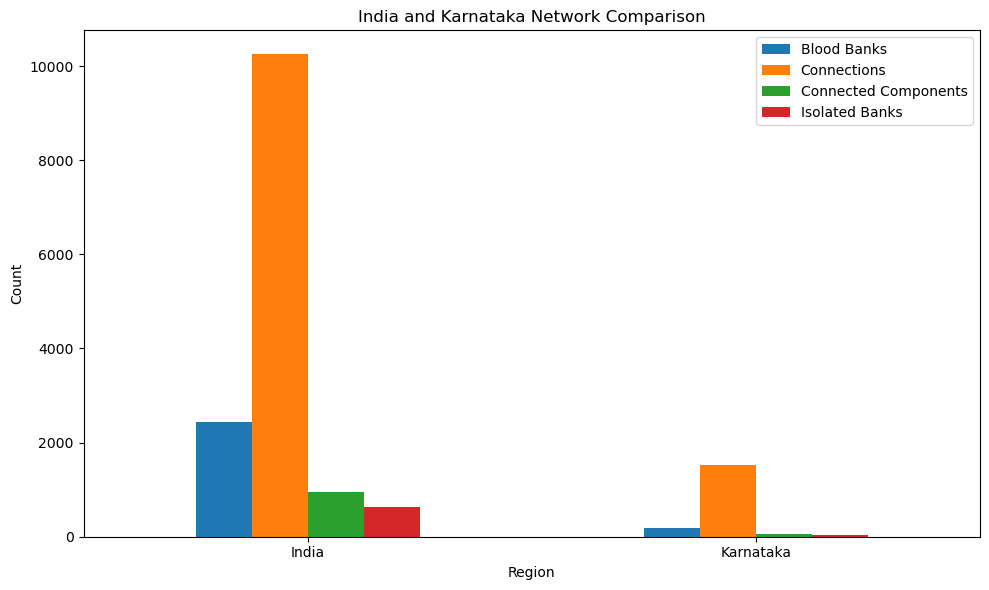

In [10]:
comparison_plot = comparison_data.set_index("Region")[
    ["Blood Banks", "Connections", "Connected Components", "Isolated Banks"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("India and Karnataka Network Comparison")
plt.ylabel("Count")
plt.xlabel("Region")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Step 10 : Save advanced network results

In [11]:
results_folder = Path("results")
results_folder.mkdir(parents=True, exist_ok=True)

# Save isolated blood banks
isolated_banks.to_csv(
    results_folder / "isolated_blood_banks.csv",
    index=False
)

# Save important blood banks
important_banks.to_csv(
    results_folder / "important_blood_banks.csv",
    index=False
)

# Save India and Karnataka comparison
comparison_data.to_csv(
    results_folder / "india_karnataka_network_comparison.csv",
    index=False
)

print("Advanced network results saved successfully!")

print("\nSaved files:")
print("- isolated_blood_banks.csv")
print("- important_blood_banks.csv")
print("- india_karnataka_network_comparison.csv")

Advanced network results saved successfully!

Saved files:
- isolated_blood_banks.csv
- important_blood_banks.csv
- india_karnataka_network_comparison.csv
